# 01 - EDA ulasan Google Play (paylater)

Tujuan: memastikan data mentah layak dipakai sebelum cleaning dan pelabelan.

Yang diperiksa: distribusi bintang, **rentang waktu per bintang**, kualitas teks, campuran bahasa, data pribadi (PII), dan kata-kata yang paling sering muncul.

> **Privasi:** hanya sel "sampel ulasan" di bawah yang menampilkan teks asli. Pakai *Clear All Outputs* sebelum notebook ini di-commit ke GitHub.


In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# cari folder proyek (yang punya src/paths.py) mulai dari lokasi notebook ini
here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(root / "src"))
from paths import FIGURES, RAW

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 200)
plt.rcParams["figure.dpi"] = 110
print("folder proyek:", root)

folder proyek: C:\Projects\paylater-review-project


## 0. Muat data

In [2]:
files = sorted(RAW.glob("*.csv"))
print([f.name for f in files])

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df["content"] = df["content"].fillna("").astype(str)

print(df.shape)
print("reviewId unik:", df["reviewId"].is_unique)
df.dtypes

['com.finaccel.android.csv', 'id.co.myhomecredit.csv', 'io.silvrr.installment.csv']
(22500, 7)
reviewId unik: True


reviewId                           str
content                            str
score                            int64
thumbsUpCount                    int64
reviewCreatedVersion               str
at                      datetime64[us]
app_id                             str
dtype: object

## 1. Distribusi bintang per aplikasi

Diambil rata per bintang, jadi tabel ini seharusnya hampir seragam. Ini **bukan** distribusi asli di Play Store.


In [3]:
pd.crosstab(df["app_id"], df["score"], margins=True)

score,1,2,3,4,5,All
app_id,,,,,,
com.finaccel.android,1500,1500,1500,1500,1500,7500
id.co.myhomecredit,1500,1500,1500,1500,1500,7500
io.silvrr.installment,1500,1500,1500,1500,1500,7500
All,4500,4500,4500,4500,4500,22500


## 2. Rentang waktu per bintang

Sort terbaru + jumlah tetap per bintang berarti bintang yang jarang (biasanya 1-2) bisa membentang jauh lebih lama daripada bintang 5. Kalau rentangnya timpang, model bisa belajar "zaman" ulasan, bukan sentimen.


terlama             terbaru  rentang_hari
app_id                score                                                      
com.finaccel.android  1     2026-08-30 11:00:06 2026-11-16 16:50:42            78
                      2     2025-07-16 10:55:47 2026-11-16 10:55:03           487
                      3     2025-09-28 13:43:17 2026-11-15 23:26:18           413
                      4     2026-04-19 19:58:18 2026-11-16 08:18:14           210
                      5     2026-11-05 03:39:08 2026-11-16 17:04:27            11
id.co.myhomecredit    1     2026-04-23 14:31:10 2026-11-16 15:15:24           207
                      2     2023-09-15 08:07:55 2026-11-16 11:12:29          1158
                      3     2023-06-25 23:46:27 2026-11-13 13:31:18          1236
                      4     2023-06-06 14:54:03 2026-11-16 09:06:25          1258
                      5     2026-05-08 17:12:44 2026-11-16 15:13:08           191
io.silvrr.installment 1     2026-09-19 14:35:05 2026-11-16 16:32:38            58
                      2     2025-11-08 20:20:40 2026-11-16 16:40:53           372
                      3     2025-09-24 17:49:32 2026-11-16 04:33:27           417
                      4     2025-12-25 08:02:19 2026-11-16 14:55:20           326
                      5     2026-10-30 18:22:53 2026-11-16 17:09:59            16

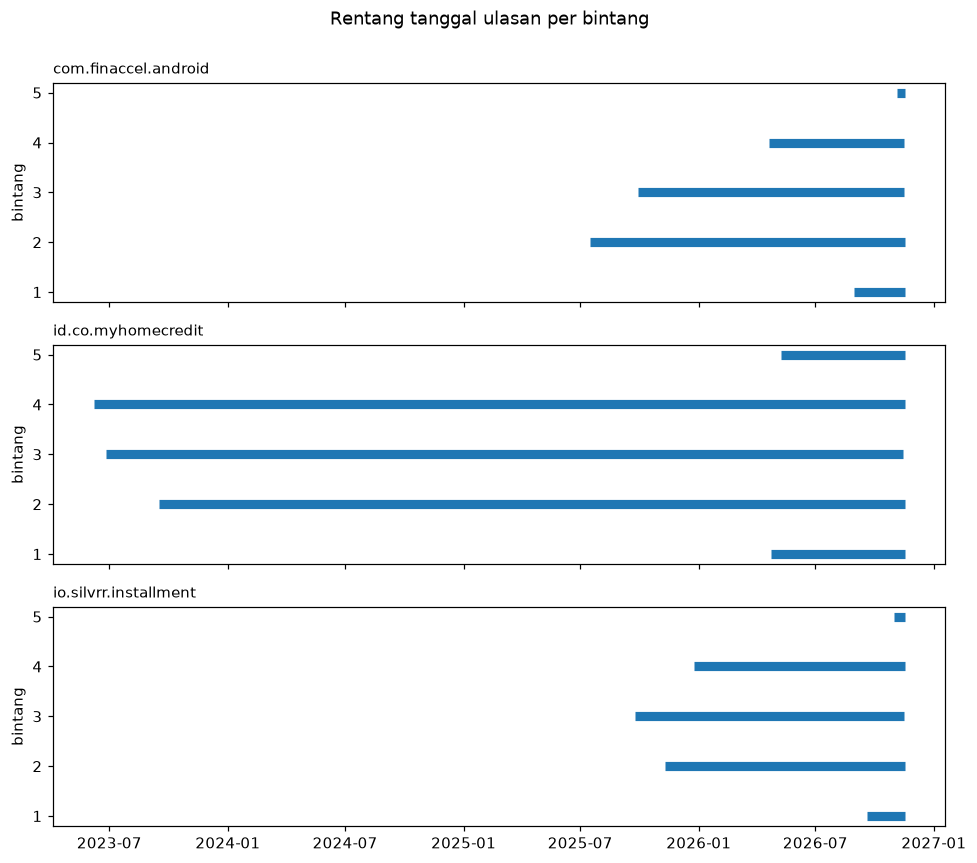

In [4]:
span = (
    df.groupby(["app_id", "score"])["at"]
    .agg(terlama="min", terbaru="max")
    .assign(rentang_hari=lambda t: (t["terbaru"] - t["terlama"]).dt.days)
)
display(span)

apps = sorted(df["app_id"].unique())
fig, axes = plt.subplots(len(apps), 1, figsize=(9, 2.6 * len(apps)), sharex=True, squeeze=False)
for ax, app in zip(axes[:, 0], apps):
    s = span.loc[app]
    ax.hlines(s.index, mdates.date2num(s["terlama"]), mdates.date2num(s["terbaru"]), linewidth=6)
    ax.xaxis_date()
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_ylabel("bintang")
    ax.set_title(app, fontsize=10, loc="left")
fig.suptitle("Rentang tanggal ulasan per bintang", y=1.0)
fig.tight_layout()
fig.savefig(FIGURES / "eda_rentang_waktu.png", bbox_inches="tight")
plt.show()

## 3. Kualitas teks

ulasan kosong: 0
teks sama persis dengan ulasan lain: 4584 (20.4%)
sebaran duplikat per bintang:
score
1     282
2     206
3     523
4    1507
5    2066

jumlah kata per bintang:


,count,mean,std,min,25%,50%,75%,max
score,,,,,,,,
1,4500.0,17.3,16.3,1.0,5.0,12.0,24.0,102.0
2,4500.0,19.0,16.1,1.0,8.0,14.0,26.0,98.0
3,4500.0,15.7,15.1,1.0,5.0,11.0,22.0,95.0
4,4500.0,8.8,11.5,1.0,2.0,4.0,11.0,103.0
5,4500.0,5.1,7.4,1.0,1.0,2.0,5.0,84.0


share ulasan <= 3 kata per bintang:
score
1    0.162
2    0.095
3    0.187
4    0.464
5    0.607


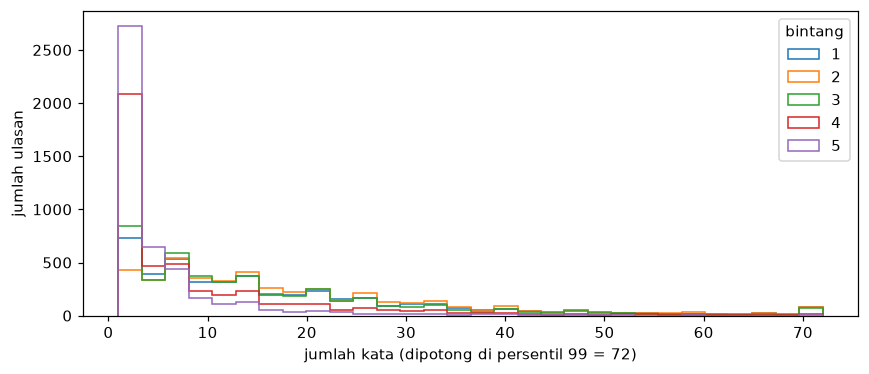

In [5]:
df["n_kata"] = df["content"].str.split().str.len()

kosong = (df["content"].str.strip() == "").sum()
print("ulasan kosong:", kosong)

norm = df["content"].str.lower().str.strip()
dup_mask = norm.duplicated(keep=False) & (norm != "")
print(f"teks sama persis dengan ulasan lain: {dup_mask.sum()} ({dup_mask.mean():.1%})")
print("sebaran duplikat per bintang:")
print(df.loc[dup_mask].groupby("score").size().to_string())

print("\njumlah kata per bintang:")
display(df.groupby("score")["n_kata"].describe().round(1))

print("share ulasan <= 3 kata per bintang:")
print((df["n_kata"] <= 3).groupby(df["score"]).mean().round(3).to_string())

cap = int(df["n_kata"].quantile(0.99))
fig, ax = plt.subplots(figsize=(8, 3.5))
for sc in sorted(df["score"].unique()):
    ax.hist(df.loc[df["score"] == sc, "n_kata"].clip(upper=cap), bins=30, histtype="step", label=f"{sc}")
ax.set_xlabel(f"jumlah kata (dipotong di persentil 99 = {cap})")
ax.set_ylabel("jumlah ulasan")
ax.legend(title="bintang")
fig.tight_layout()
fig.savefig(FIGURES / "eda_panjang_ulasan.png", bbox_inches="tight")
plt.show()

## 4. Bahasa dan noise

Heuristik sederhana berbasis kata umum (bukan detektor bahasa sungguhan). Cukup untuk melihat seberapa banyak ulasan yang jelas bukan bahasa Indonesia.


In [6]:
ID_WORDS = {
    "yang", "dan", "di", "ke", "dari", "untuk", "dengan", "ini", "itu", "tidak", "gak", "ga", "nggak",
    "enggak", "saya", "aku", "kok", "banget", "sudah", "udah", "belum", "bisa", "tapi", "karena", "juga",
    "atau", "kenapa", "tolong", "bagus", "jelek", "mudah", "susah", "ribet", "lama", "mau", "pakai",
    "pake", "sih", "dong", "nih", "jadi", "ada", "cuma", "hanya", "sangat", "sekali", "aplikasi",
    "limit", "tagihan", "bunga", "akun", "tidak", "lagi", "sama", "aja", "saja", "pas", "nya",
}
EN_WORDS = {
    "the", "and", "is", "are", "this", "that", "not", "very", "good", "bad", "to", "of", "for", "with",
    "it", "i", "my", "you", "can", "cannot", "please", "fix", "why", "but", "so", "have", "was", "been",
}


def tebak_bahasa(teks):
    kata = re.findall(r"[a-zA-Z']+", teks.lower())
    n_id = sum(k in ID_WORDS for k in kata)
    n_en = sum(k in EN_WORDS for k in kata)
    if n_id == 0 and n_en == 0:
        return "tidak jelas"
    return "id" if n_id >= n_en else "en"


df["bahasa"] = df["content"].map(tebak_bahasa)
pd.crosstab(df["app_id"], df["bahasa"], normalize="index").round(3)

bahasa,en,id,tidak jelas
app_id,,,
com.finaccel.android,0.013,0.759,0.228
id.co.myhomecredit,0.019,0.809,0.172
io.silvrr.installment,0.010,0.806,0.184


## 5. Data pribadi (PII) di dalam teks

Hanya menghitung, tidak menampilkan isinya. Hasilnya menentukan seberapa penting langkah masking di tahap cleaning.


In [7]:
PII = {
    "telepon": re.compile(r"(?<!\d)(?:\+?62|0)8\d{8,11}(?!\d)"),
    "email": re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+"),
    "angka >= 10 digit (rekening/NIK?)": re.compile(r"(?<!\d)\d{10,}(?!\d)"),
}
pii = pd.DataFrame({nama: df["content"].str.contains(pola) for nama, pola in PII.items()})
display(pii.groupby(df["app_id"]).sum())
print(f"ulasan yang mengandung salah satunya: {pii.any(axis=1).mean():.1%}")

,telepon,email,angka >= 10 digit (rekening/NIK?)
app_id,,,
com.finaccel.android,0,1,0
id.co.myhomecredit,0,0,0
io.silvrr.installment,0,0,0


ulasan yang mengandung salah satunya: 0.0%


## 6. Kata teratas: keluhan (1-2) vs pujian (4-5)

Gambaran awal tentang topik dan kata slang sebelum topic modeling. Daftar stopword di sini sengaja sederhana.


In [8]:
STOP = ID_WORDS | EN_WORDS | {"nya", "yg", "yang", "tau", "apa", "bgt", "udah", "aja", "kalo", "kalau", "gue", "jadi", "banget"}


def kata_teratas(teks, n=15):
    hitung = Counter(
        k for t in teks for k in re.findall(r"[a-z]{3,}", t.lower()) if k not in STOP
    )
    return ", ".join(k for k, _ in hitung.most_common(n))


baris = {}
for app, g in df.groupby("app_id"):
    baris[(app, "bintang 1-2")] = kata_teratas(g.loc[g["score"] <= 2, "content"])
    baris[(app, "bintang 4-5")] = kata_teratas(g.loc[g["score"] >= 4, "content"])
pd.Series(baris, name="kata teratas").to_frame()

kata teratas
com.finaccel.android  bintang 1-2             kredivo, bayar, padahal, telat, data, tolak, pernah, malah, pinjaman, bulan, hari, tiba, pembayaran, transaksi, selalu
                      bintang 4-5            membantu, kredivo, mantap, cepat, baik, kasih, bayar, puas, pinjaman, bintang, semoga, baru, terimakasih, padahal, naik
id.co.myhomecredit    bintang 1-2                        home, bayar, login, credit, padahal, data, terus, pernah, hari, kredit, hapus, masuk, pengajuan, apk, malah
                      bintang 4-5             home, membantu, credit, mantap, baik, cepat, kasih, semoga, pengajuan, kredit, dapat, bayar, pernah, pinjaman, padahal
io.silvrr.installment bintang 1-2                bayar, pinjaman, padahal, akulaku, malah, telat, pinjam, pernah, tolak, tempo, pengajuan, jatuh, apk, selalu, terus
                      bintang 4-5  membantu, akulaku, pinjaman, mantap, cepat, bayar, padahal, baik, kasih, pinjam, pembayaran, tempo, jatuh, pengajuan, terimakasih

## 7. Ringkasan angka

Salin keluaran sel ini ke Claude untuk dibahas bersama.


In [9]:
ringkasan = {
    "total ulasan": len(df),
    "jumlah aplikasi": df["app_id"].nunique(),
    "ulasan kosong": int(kosong),
    "teks duplikat (%)": round(dup_mask.mean() * 100, 1),
    "<= 3 kata (%)": round((df["n_kata"] <= 3).mean() * 100, 1),
    "bukan terdeteksi Indonesia (%)": round((df["bahasa"] != "id").mean() * 100, 1),
    "mengandung PII (%)": round(pii.any(axis=1).mean() * 100, 1),
    "rentang hari terpanjang": int(span["rentang_hari"].max()),
    "rentang hari terpendek": int(span["rentang_hari"].min()),
}
pd.Series(ringkasan)

total ulasan                      22500.0
jumlah aplikasi                       3.0
ulasan kosong                         0.0
teks duplikat (%)                    20.4
<= 3 kata (%)                        30.3
bukan terdeteksi Indonesia (%)       20.8
mengandung PII (%)                    0.0
rentang hari terpanjang            1258.0
rentang hari terpendek               11.0
dtype: float64

In [12]:
tj = df[df["bahasa"] == "tidak jelas"]
print("share <=3 kata di 'tidak jelas':", round((tj["n_kata"] <= 3).mean(), 3))
tj.sample(15, random_state=0)[["score", "content"]]

share <=3 kata di 'tidak jelas': 0.846


,score,content
5413,4,👍
17811,2,sulit mengajukan pinjaman
21959,5,jos
6317,5,terbaik
11909,3,Baik
21274,5,mantap
9726,2,Coba
6808,5,baik
875,1,blokir ya👍👍👍
14191,5,👍👍


## 8. Sampel ulasan 


In [11]:
df.sample(10, random_state=0)[["app_id", "score", "content"]]

,app_id,score,content
13500,id.co.myhomecredit,4,Kalo di acc nanti tak tambahjn bintangnta
18180,io.silvrr.installment,2,skor kridit yg seperti apa padahal bayar sebelom tanggal jatuh tempo tapi pengajuan di tolak alasan skor kredit😏😏😏
8710,id.co.myhomecredit,1,"bunganya sangat tinggi sekali misal cicilan 3 jt ditotal 12 bulan jadi 6 jt gila bet, mending jangan kredit disini, diteror terus juga pdahal baru ninggak 2 harian"
12361,id.co.myhomecredit,4,ok bagus
18063,io.silvrr.installment,2,kenapa saya tidak bisa bayar pakai va bca
6285,com.finaccel.android,5,sangat baik
5770,com.finaccel.android,4,baru mulai mencoba KREDIVO semoga aman
6619,com.finaccel.android,5,"terimakasih kredivo, sangat membantu"
15842,io.silvrr.installment,1,"makin hari makin ngk jelas nih apk, semua limit nya ngk bisa di pakai, padahal sebelum"" nya lancar"
8672,id.co.myhomecredit,1,semenjak ambil langsung d teror dgn nomor tida dikenal
